# Project 4A: Image Warping and Mosaicing
Code lives in `homography.py`; this notebook runs it on my photos.

In [5]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import matplotlib.pyplot as plt
import skimage.io as skio
from homography import (build_system, computeH, apply_H, reprojection_error,
                        select_points, save_points, load_points, plot_correspondences)
%matplotlib inline

os.makedirs("points", exist_ok=True)
os.makedirs("generated_outputs", exist_ok=True)

SETS = {
    "set1_room":    ("media/IMG_4479.jpg", "media/IMG_4480.jpg"),
    "set2_hallway": ("media/IMG_4484.jpg", "media/IMG_4485.jpg"),
    "set3_balcony": ("media/IMG_4486.jpg", "media/IMG_4487.jpg"),
}
images = {name: (skio.imread(a), skio.imread(b)) for name, (a, b) in SETS.items()}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## A.2: Recover Homographies


In [6]:
N_POINTS = 10

%matplotlib osx
for name, (im1, im2) in images.items():
    path = f"points/{name}.json"
    if os.path.exists(path):
        continue
    p1, p2 = select_points(im1, im2, N_POINTS)
    save_points(path, p1, p2)
    print("saved", path)
%matplotlib inline

### Computing H

Stacking all $n$ points gives a $2n \times 8$ system $A\mathbf{h} = \mathbf{b}$, solved with least squares.

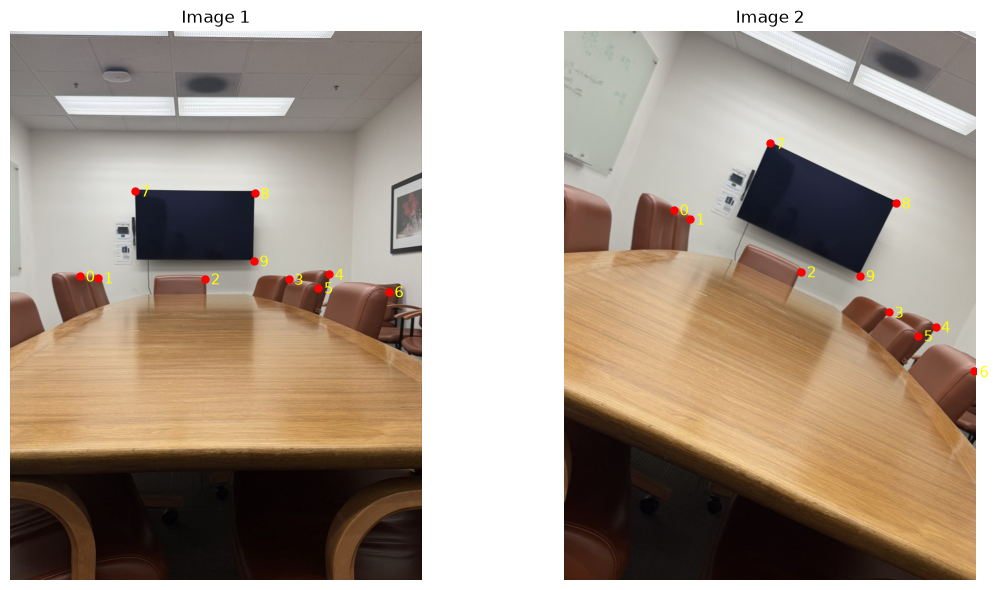

=== set1_room: 10 points, A is 20x8 ===
First two rows of A | b:
[[    203.3961     713.7857       1.           0.           0.           0.      -64777.6968 -227326.8451     318.4805]
 [      0.           0.           0.         203.3961     713.7857       1.     -105822.7664 -371367.8752     520.2792]]
H =
[[   1.0938   -0.5126  450.917 ]
 [   0.5329    1.0805 -371.4415]
 [   0.0001   -0.        1.    ]]
reprojection error: mean 8.76 px, max 20.01 px



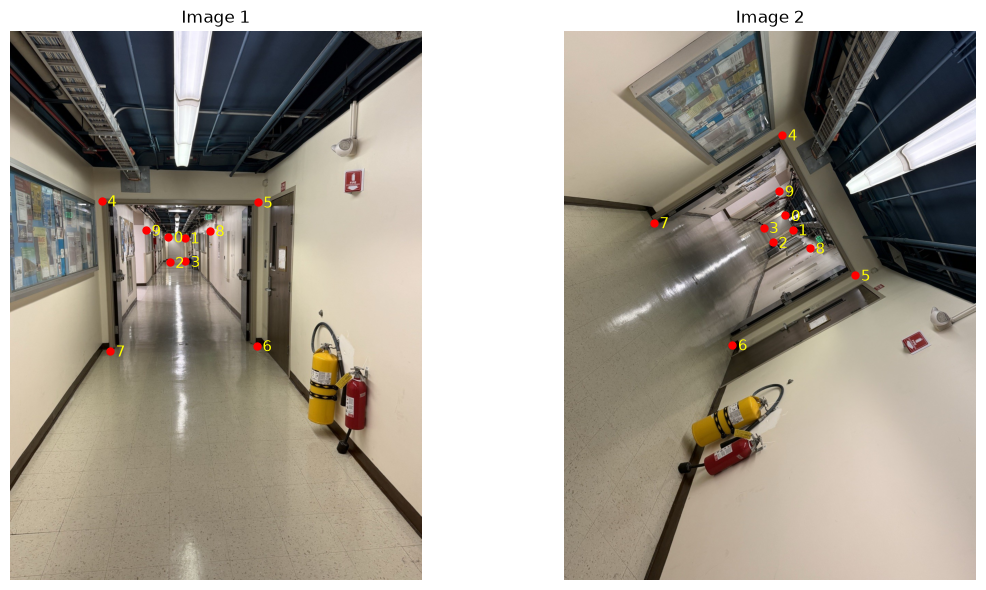

=== set2_hallway: 10 points, A is 20x8 ===
First two rows of A | b:
[[    460.539      599.5          1.           0.           0.           0.     -296428.5937 -385871.6786     643.6558]
 [      0.           0.           0.         460.539      599.5          1.     -247384.1849 -322028.8214     537.1623]]
H =
[[  0.3809  -0.841  875.6602]
 [  0.7023   0.2787 -37.7704]
 [ -0.      -0.0002   1.    ]]
reprojection error: mean 18.54 px, max 51.30 px



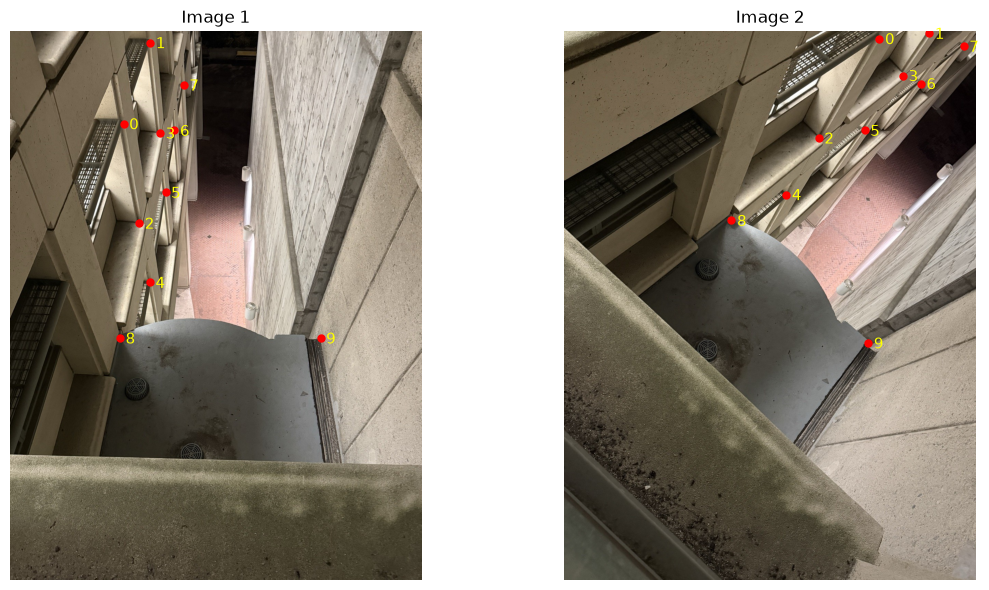

=== set3_balcony: 10 points, A is 20x8 ===
First two rows of A | b:
[[    330.6688     269.6299       1.           0.           0.           0.     -303448.7742 -247434.4295     917.6818]
 [      0.           0.           0.         330.6688     269.6299       1.       -7135.1463   -5818.0523      21.5779]]
H =
[[  0.0905  -0.6631 882.2824]
 [  0.0217   0.4605 -47.0663]
 [ -0.0005  -0.0002   1.    ]]
reprojection error: mean 36.97 px, max 84.52 px



In [7]:
np.set_printoptions(precision=4, suppress=True, linewidth=150)
H_all = {}
for name, (im1, im2) in images.items():
    p1, p2 = load_points(f"points/{name}.json")
    plot_correspondences(im1, im2, p1, p2, out_path=f"generated_outputs/a2_correspondences_{name}.png")

    A, b = build_system(p1, p2)
    H = computeH(p1, p2)
    H_all[name] = H
    err = reprojection_error(H, p1, p2)

    print(f"=== {name}: {len(p1)} points, A is {A.shape[0]}x{A.shape[1]} ===")
    print("First two rows of A | b:")
    print(np.hstack([A[:2], b[:2, None]]))
    print("H =")
    print(H)
    print(f"reprojection error: mean {err.mean():.2f} px, max {err.max():.2f} px\n")

## A.3: Warp the Images

warpImageNearestNeighbor(im, H) and warpImageBilinear(im, H) in warp.py use inverse warping. They map the
four corners of im through $H$ to get the output bounding box. Then, for every output pixel, they apply
$H^{-1}$ to find where it came from in im and sample there:
- **Nearest neighbor:** round the source coordinate to the closest pixel.
- **Bilinear:** take a weighted average of the 4 surrounding pixels, weighted by distance.

Each function returns (warped, alpha, offset). alpha is 1 where the output pixel came from inside im
and 0 where it's empty, and offset is the output's top-left corner in the target frame.

In [8]:
from warp import (warpImageNearestNeighbor, warpImageBilinear, rectify, rectangle_size,
                  select_corners, save_corners, load_corners, with_alpha)
import time

RECT = {
    "tv":    "media/IMG_4480.jpg",
    "board": "media/IMG_4485.jpg",
}
SIZE = {
    "tv": None,
    "board": None,
}
MARGIN = 150

%matplotlib osx
for name, path in RECT.items():
    out = f"points/rect_{name}.json"
    if os.path.exists(out):
        continue
    save_corners(out, select_corners(skio.imread(path)))
    print("saved", out)
%matplotlib inline

saved points/rect_tv.json
saved points/rect_board.json


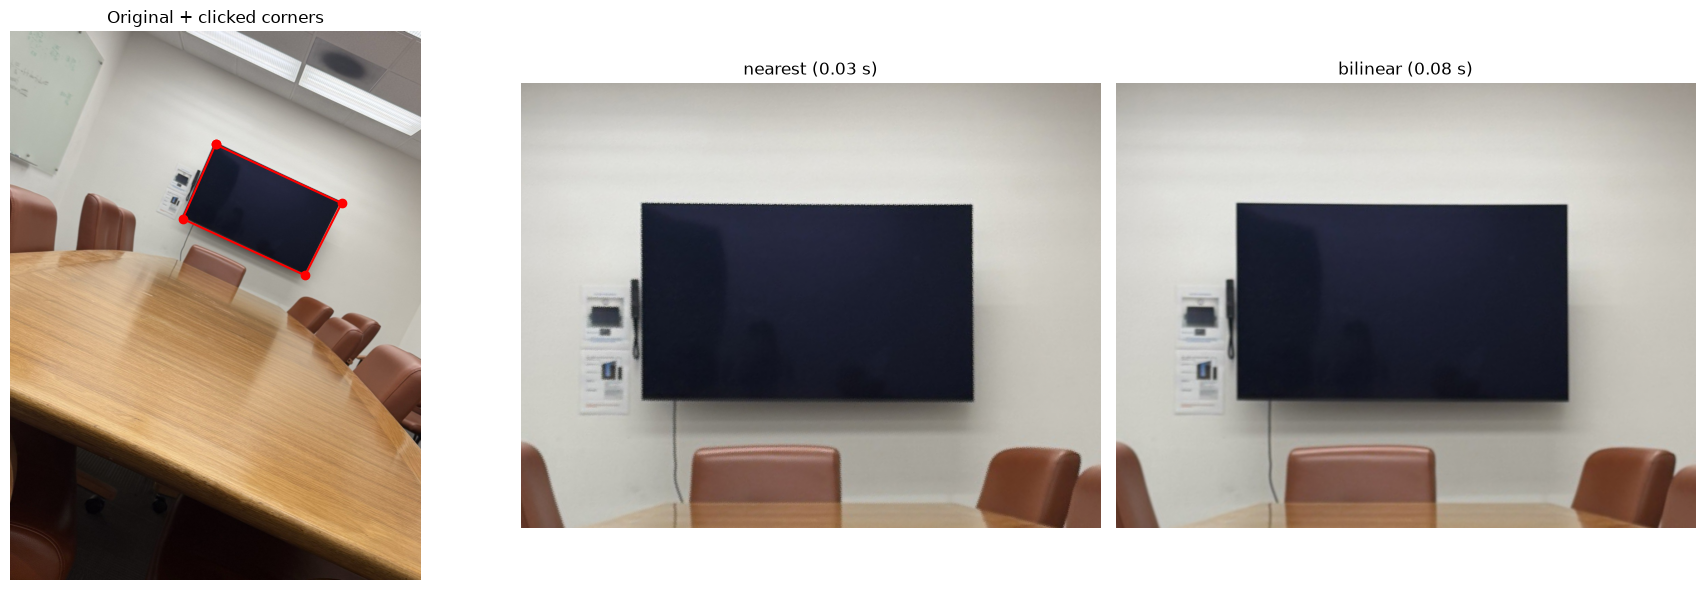

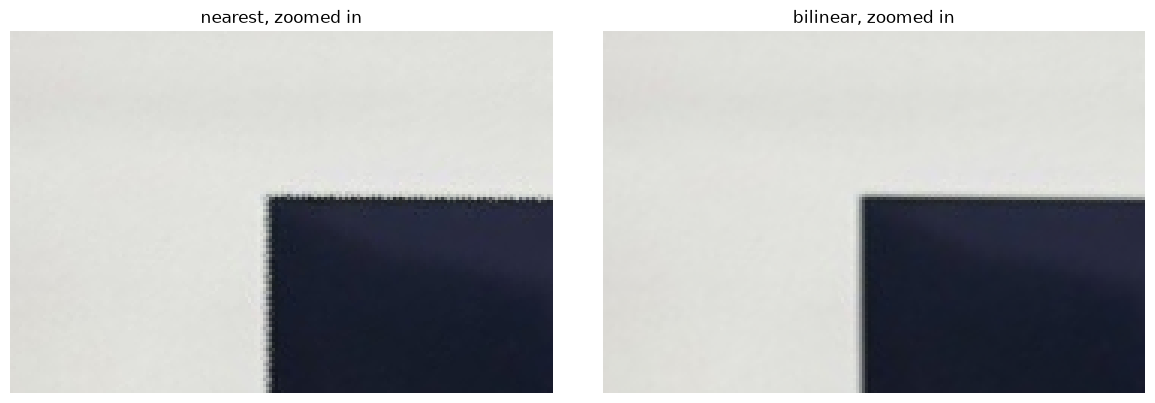

tv: H =
[[   0.877     0.3886 -653.3146]
 [  -0.4013    0.8603  -42.9958]
 [   0.       -0.0001    1.    ]]



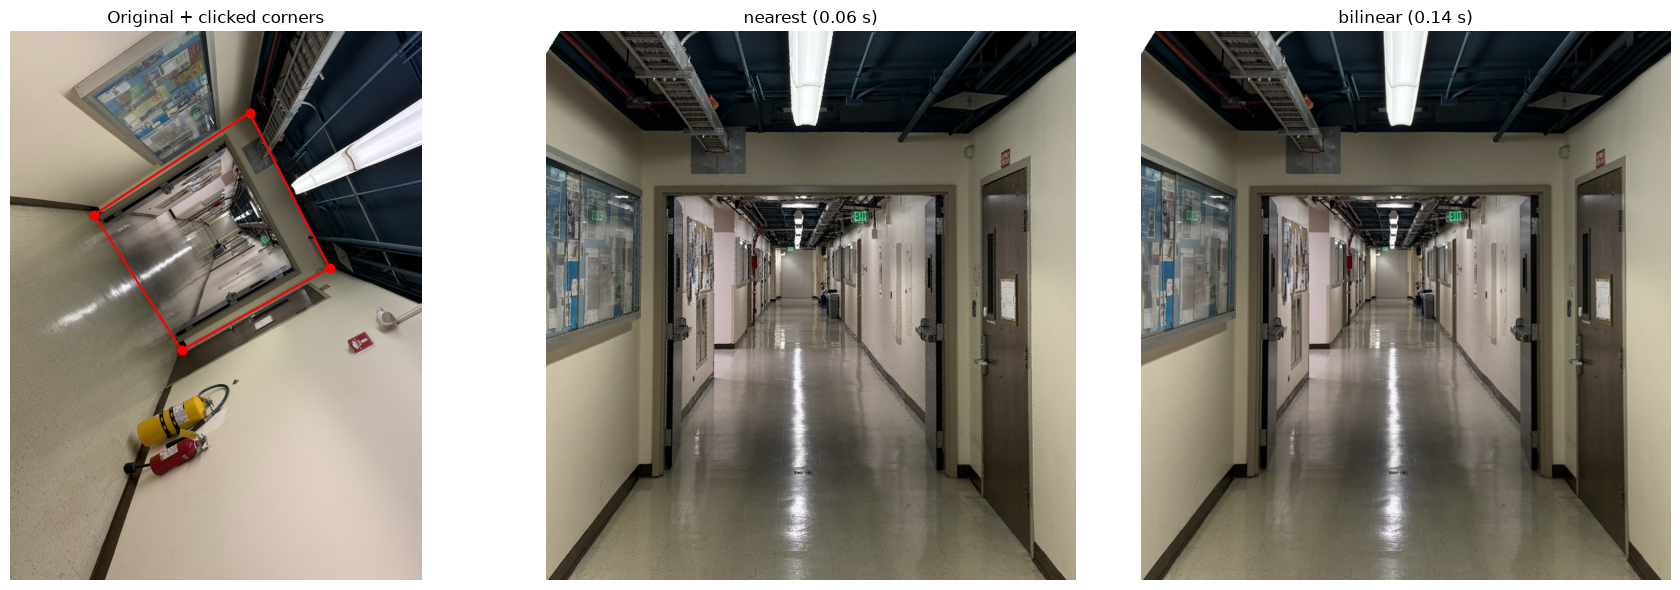

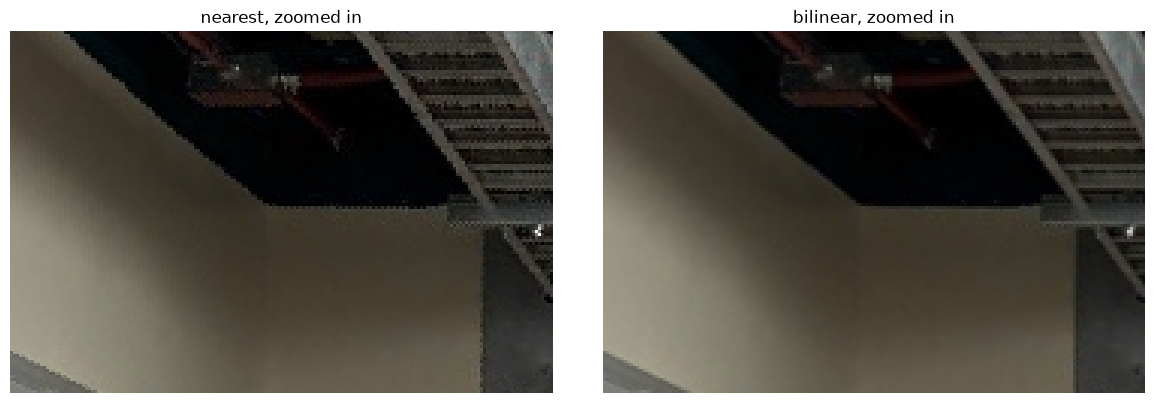

board: H =
[[   0.4666    0.7111 -494.4123]
 [  -0.7616    0.3939  438.3233]
 [   0.       -0.0002    1.    ]]



In [9]:
for name, path in RECT.items():
    im = skio.imread(path)
    corners = load_corners(f"points/rect_{name}.json")
    w, h = SIZE[name] or rectangle_size(corners)

    results = {}
    for label, fn in [("nearest", warpImageNearestNeighbor), ("bilinear", warpImageBilinear)]:
        t = time.time()
        out, alpha, H = rectify(im, corners, w, h, warp=fn, margin=MARGIN)
        results[label] = (out, alpha, time.time() - t)
        skio.imsave(f"generated_outputs/a3_rect_{name}_{label}.png",
                    (with_alpha(out, alpha) * 255).astype(np.uint8), check_contrast=False)

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    ax[0].imshow(im)
    ax[0].plot(*np.vstack([corners, corners[:1]]).T, "r-o")
    ax[0].set_title("Original + clicked corners")
    for a, (label, (out, alpha, dt)) in zip(ax[1:], results.items()):
        a.imshow(with_alpha(out, alpha))
        a.set_title(f"{label} ({dt:.2f} s)")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.savefig(f"generated_outputs/a3_rect_{name}_comparison.png", bbox_inches="tight", dpi=150)
    plt.show()

    cy, cx = MARGIN, MARGIN
    crop = np.s_[cy - 60:cy + 60, cx - 90:cx + 90]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (label, (out, alpha, dt)) in zip(ax, results.items()):
        a.imshow(np.clip(out[crop], 0, 1), interpolation="nearest")
        a.set_title(f"{label}, zoomed in")
        a.axis("off")
    plt.tight_layout()
    plt.savefig(f"generated_outputs/a3_rect_{name}_zoom.png", bbox_inches="tight", dpi=150)
    plt.show()

    print(f"{name}: H =\n{H}\n")

## A.4: Blend the Images into a Mosaic

Image 1 of each set is the reference, so it stays where it is (homography $I$). Image 2 is warped into
image 1's frame with $H^{-1}$, because $H$ from A.2 maps image 1 points to image 2. Both images are warped onto
one shared canvas, the union of their warped bounding boxes, so they line up pixel for pixel.

Every pixel gets a weight: its distance to the nearest edge of its own image. The weight is 1 in the middle and
falls toward 0 at the borders, and it's warped along with the image.

**Two-band blending:** split each image into a low band (Gaussian blur) and a high band (image minus blur).
The low bands are averaged using the weights, so color and brightness change smoothly across the overlap
without a visible seam. Each high-band pixel comes from the image with the biggest weight there, so edges stay
sharp instead of doubling up when the alignment is slightly off.


set1_room: canvas 1512x1619, 1.8 s


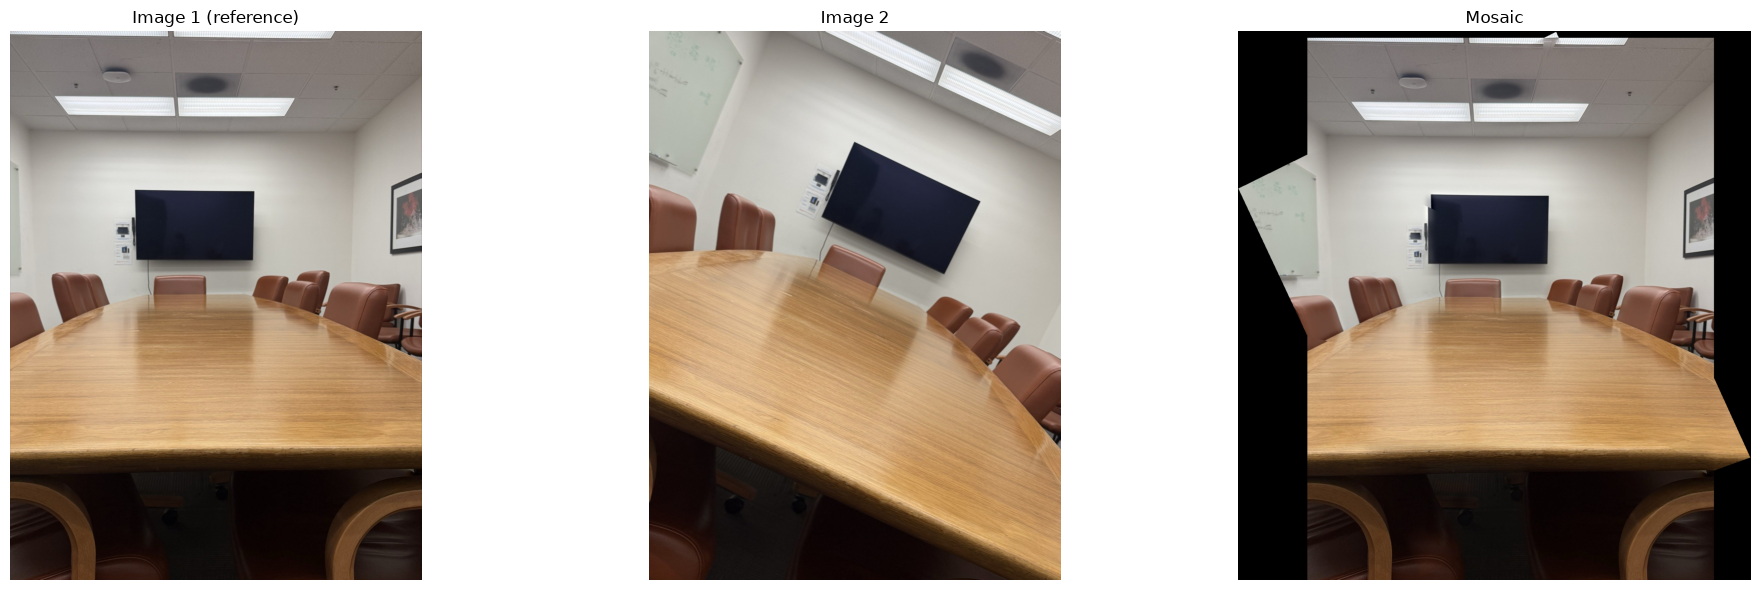

set2_hallway: canvas 1946x2007, 2.5 s


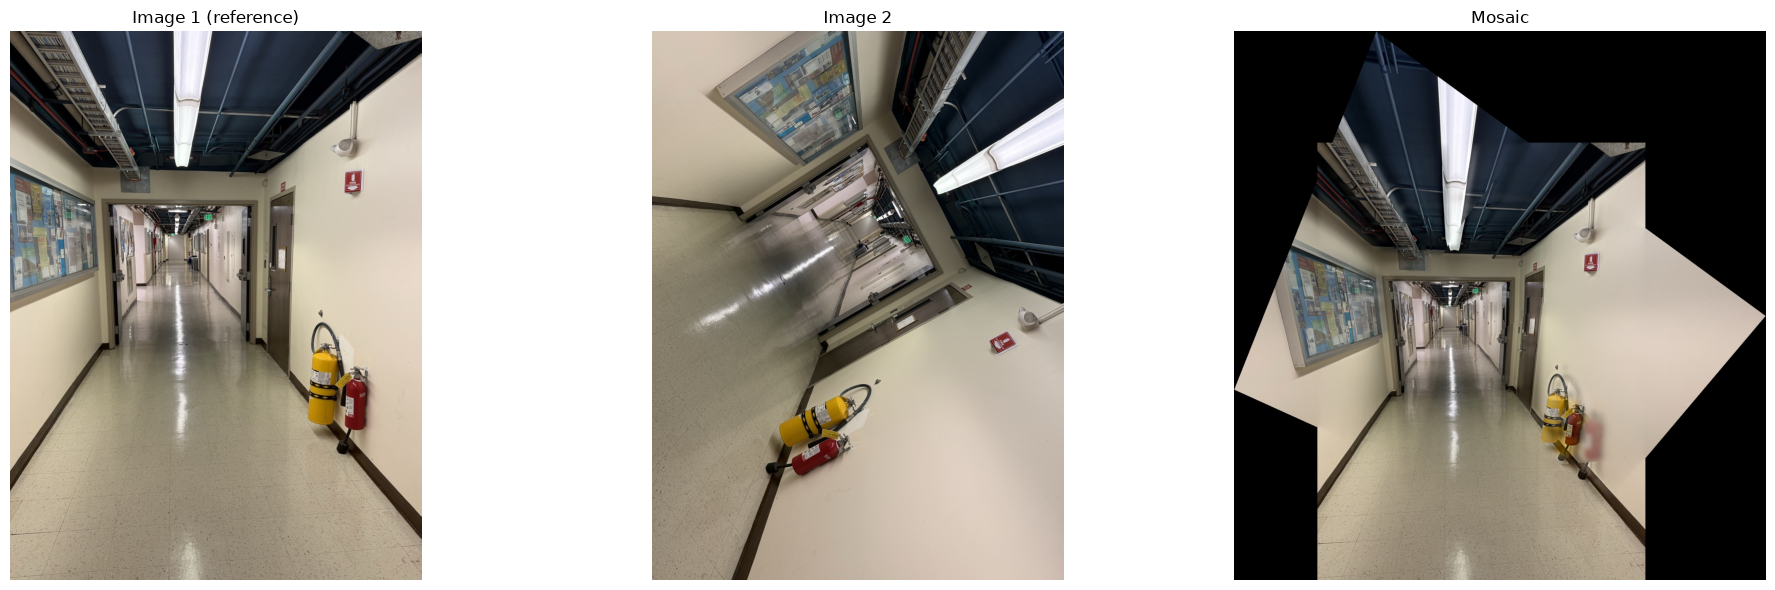

set3_balcony: canvas 2166x2378, 3.4 s


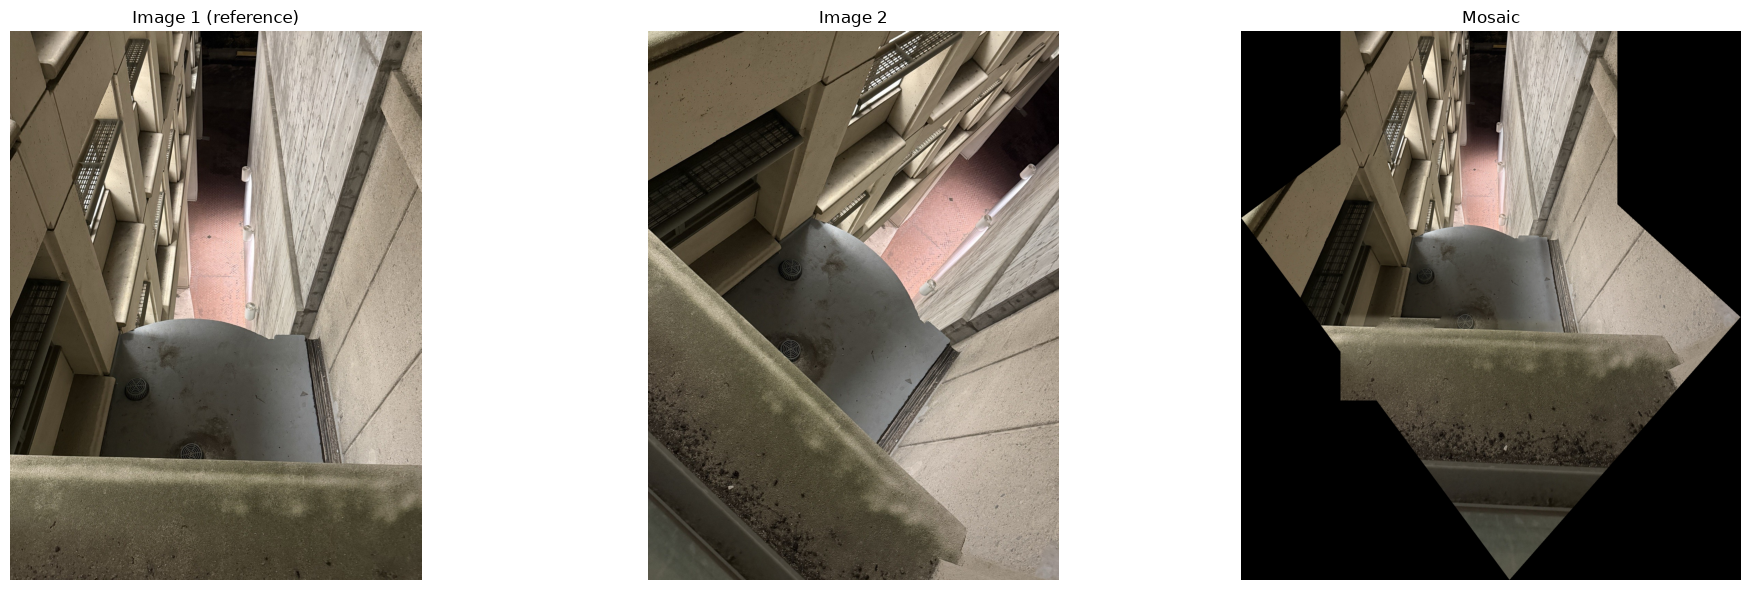

In [11]:
from mosaic import mosaic
from PIL import Image

for name, (im1, im2) in images.items():
    p1, p2 = load_points(f"points/{name}.json")
    H = computeH(p1, p2)
    Hinv = np.linalg.inv(H)
    Hinv /= Hinv[2, 2]

    t = time.time()
    out, alpha, layers, bbox = mosaic([im1, im2], [np.eye(3), Hinv])
    Image.fromarray((out * 255).astype(np.uint8)).save(f"generated_outputs/a4_mosaic_{name}.jpg", quality=90)
    print(f"{name}: canvas {out.shape[1]}x{out.shape[0]}, {time.time() - t:.1f} s")

    fig, ax = plt.subplots(1, 3, figsize=(20, 6))
    for a, im, title in zip(ax, [im1, im2, out], ["Image 1 (reference)", "Image 2", "Mosaic"]):
        a.imshow(im)
        a.set_title(title)
        a.axis("off")
    plt.tight_layout()
    plt.savefig(f"generated_outputs/a4_mosaic_{name}_comparison.png", bbox_inches="tight", dpi=120)
    plt.show()